
# Quantum Magnetometry Using Machine Learning

### 1. Introduction

Quantum magnetometry uses quantum systems to measure weak magnetic fields with high precision. A quantum sensor can encode information about an external magnetic field into the relative phase of a quantum state. By measuring this phase, we can estimate the unknown magnetic field. In this project, we simulate a single-qubit Ramsey magnetometer and investigate how machine learning can be used to estimate an unknown magnetic field from its measurement outcomes.  




### 2. Ramsey Interferometry

Consider a two-level quantum system with basis states |0> and |1>. The qubit is initially prepared in the ground state: $|\psi_0\rangle = |0\rangle $

State preparation: A Hadamard gate creates an equal superposition: $H|0\rangle = \frac{|0\rangle+|1\rangle}{\sqrt{2}}$

The qubit interacts with an external magnetic field B for an interrogation time t. The magnetic field causes a relative phase $\phi(B,t)=\gamma Bt$ to accumulate, where B is the magnetic field, t is the interrogation time, gamma is the effective gyromagnetic ratio, phi is the accumulated phase.  
The resulting state is $|\psi_1\rangle = \frac{|0\rangle+e^{i\phi}|1\rangle}{\sqrt{2}} $

A second Hadamard gate converts the relative phase into a measurable population difference. The final state is $|\psi_2\rangle = \frac{1}{2}\left[(1+e^{i\phi})|0\rangle + (1-e^{i\phi})|1\rangle\right]$  
Therefore, the probability of measuring |1> is $P(1|B,t)=\sin^2\left(\frac{\phi}{2}\right)$  
Substituting the accumulated phase, ${P(1|B,t)=\frac{1-\cos(\gamma Bt)}{2}}$


### 3. Effect of Decoherence

In a real quantum sensor, interaction with the environment causes the loss of quantum coherence.The coherence time T2 characterizes the timescale over which the phase coherence of the qubit is maintained. We model the decay of Ramsey fringe contrast using $V(t)=e^{-t/T_2}$ where V(t) is the visibility of the interference signal. The measurement probability becomes

$$
{
P(1|B,t)=
\frac{1}{2}
\left[
1-e^{-t/T_2}\cos(\gamma Bt)
\right]
}
$$



In [6]:
import numpy as np
import matplotlib.pyplot as plt


rng = np.random.default_rng(42)

# Effective gyromagnetic ratio (rad/s/T)
# Illustrative electron-spin-like value
gamma = 2*np.pi*28e9
T2 = 1e-3  # Coherence time
B = 25e-9  # Example B
t = 100e-6 # Interrogation time

print("Gyromagnetic ratio: ", gamma, " rad/s/T")
print("Coherence time: ", T2*1e3, " ms")
print("Magnetic field: ", B*1e9, " nT")
print("Interrogation time: ", t*1e6, " us")

Gyromagnetic ratio:  175929188601.0284  rad/s/T
Coherence time:  1.0  ms
Magnetic field:  25.0  nT
Interrogation time:  100.0  us


In [7]:
def calculate_phase(B, t, g=gamma):
    return g*B*t

phase = calculate_phase(B, t)
print("Accumulated phase = ", phase," radians")

Accumulated phase =  0.43982297150257105  radians


In [8]:
def measurement_prob(B, t, T2=T2, g=gamma):
    
    # Probability of measuring |1> after a Ramsey sequence, including exponential decoherence.
    
    if t < 0:
        print("Interrogation time cannot be negative.")

    if T2 <= 0:
        print("T2 must be positive.")

    phase = g*np.asarray(B)*t
    visibility = np.exp(-t/T2)
    probability = 0.5*(1 - visibility*np.cos(phase))
    return probability

p1 = measurement_prob(B, t)

print("Probability of measuring |1>: ", p1)
print("Probability of measuring |0>: ", 1-p1)

Probability of measuring |1>:  0.09063931303877959
Probability of measuring |0>:  0.9093606869612204


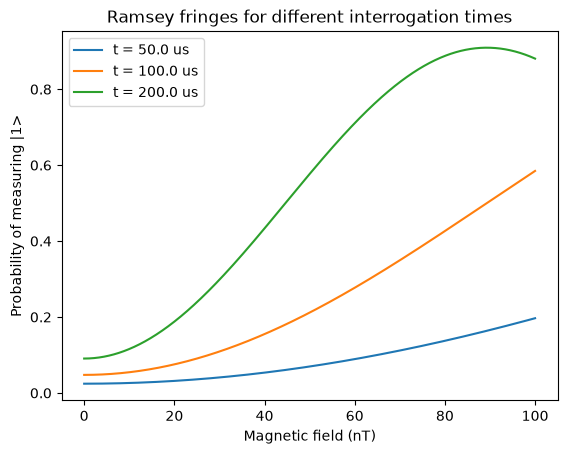

In [9]:
B_values = np.linspace(0, 100e-9, 1000)
times = [50e-6, 100e-6, 200e-6]

for interrogation_time in times:
    probabilities = measurement_prob(B_values, interrogation_time, T2)
    plt.plot(B_values * 1e9, probabilities, label="t = "+str(interrogation_time*1e6)+" us")

plt.xlabel("Magnetic field (nT)")
plt.ylabel("Probability of measuring |1>")
plt.title("Ramsey fringes for different interrogation times")
plt.legend()
plt.show()

In [11]:
def simulate_measurements(B, t, T2=T2, shots=1000, rng=rng):

    if shots <= 0:
        print("Number of shots must be positive.")

    p1 = measurement_prob(B, t, T2)
    outcomes = rng.binomial(n=1, p=p1, size=shots)
    return outcomes

shots = 1000
measurements = simulate_measurements(B=B, t=t, T2=T2, shots=shots)
measured_probability = np.mean(measurements)
theoretical_probability = measurement_prob(B, t, T2)

print("Measurement results")
print("Theoretical P(1): ", theoretical_probability)
print("Measured P(1):    ", measured_probability)
print("Number of shots:  ", shots)
print("Number of 1s:     ", np.sum(measurements))
print("Number of 0s:     ", shots - np.sum(measurements))

Measurement results
Theoretical P(1):  0.09063931303877959
Measured P(1):     0.089
Number of shots:   1000
Number of 1s:      89
Number of 0s:      911


In [ ]:
shot_numbers = [10, 50, 100, 500, 1000, 5000, 10000]
observed_probabilities = []

for n in shot_numbers:
    outcomes = simulate_measurements(B=B, t=t, T2=T2, shots=n)
    observed_probabilities.append(np.mean(outcomes))


plt.plot(shot_numbers, observed_probabilities, "o-", label="Observed probability")
plt.axhline(theoretical_probability, linestyle="--", label="Theoretical probability")

plt.xscale("log")
plt.xlabel("Number of measurements (shots)")
plt.ylabel("Estimated probability of measuring |1>")
plt.title("Effect of shot noise on measurement probability")
plt.legend()
plt.show()

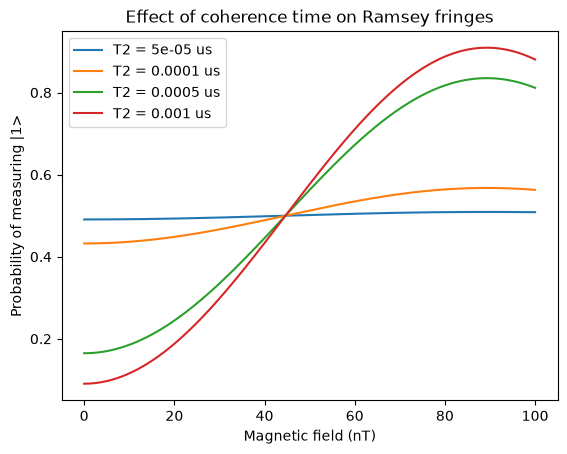

In [12]:
T2_values = [50e-6, 100e-6, 500e-6, 1e-3]
for coherence_time in T2_values:
    probabilities = measurement_prob(B_values, t=200e-6, T2=coherence_time)
    plt.plot(B_values * 1e9, probabilities, label="T2 = "+str(coherence_time)+" us")

plt.xlabel("Magnetic field (nT)")
plt.ylabel("Probability of measuring |1>")
plt.title("Effect of coherence time on Ramsey fringes")
plt.legend()
plt.show()


## 4. Results and Discussion
 
The simulations demonstrate the following

1. Magnetic-field-dependent phase accumulation: The accumulated phase increases linearly with both the    magnetic field and the interrogation time.

2. Ramsey fringes: The probability of measuring |1> oscillates with the magnetic field because the  accumulated phase is periodic.

3. Interrogation time: Increasing the interrogation time increases the phase accumulated for a given magnetic field. However, it also increases exposure to decoherence.

4. Shot noise: Repeated measurements produce statistical fluctuations. Increasing the number of shots improves the precision of the estimated measurement probability.

5. Coherence time: A longer coherence time preserves the visibility of the Ramsey fringes and can improve the sensing performance.